<a href="https://colab.research.google.com/github/Lindaoctaviani7/Lindaoctaviani7-Machine-learning_Ganjil_TI3B_2026_244107020002/blob/main/TugasPraktikum_JS4_Pertemuan5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Laporan Praktikum Clustering K-Means & DBSCAN
1. K-Means Clustering menggunakan dataset Mall_Customers.csv.
2. DBSCAN Clustering menggunakan dataset sintetis make_moons beserta eksperimen parameter.



JAWABAN TUGAS 1 K-Means (Mall Customers)

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Load Data
df = pd.read_csv('/content/drive/MyDrive/Data Saya/semester 5/pembelajaran mesin/Mall_Customers.csv')
display(df.head())
print(df.info())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


Pemilihan Fitur
Untuk clustering pelanggan, kita akan memilih fitur Annual Income (k$) dan Spending Score (1-100). Kedua fitur ini sangat representatif untuk mengelompokkan perilaku belanja konsumen berdasarkan tingkat pendapatan mereka.


In [15]:
# Memilih fitur indeks ke-3 dan ke-4 (Annual Income dan Spending Score)
X_kmeans = df.iloc[:, [3, 4]].values

# Standarisasi fitur
scaler_kmeans = StandardScaler()
X_kmeans_scaled = scaler_kmeans.fit_transform(X_kmeans)

Menentukan Jumlah Klaster (k) Terbaik
Kita akan menganalisis jumlah klaster menggunakan Elbow Method (melihat nilai Within-Cluster Sum of Square / WCSS) dan Silhouette Score.

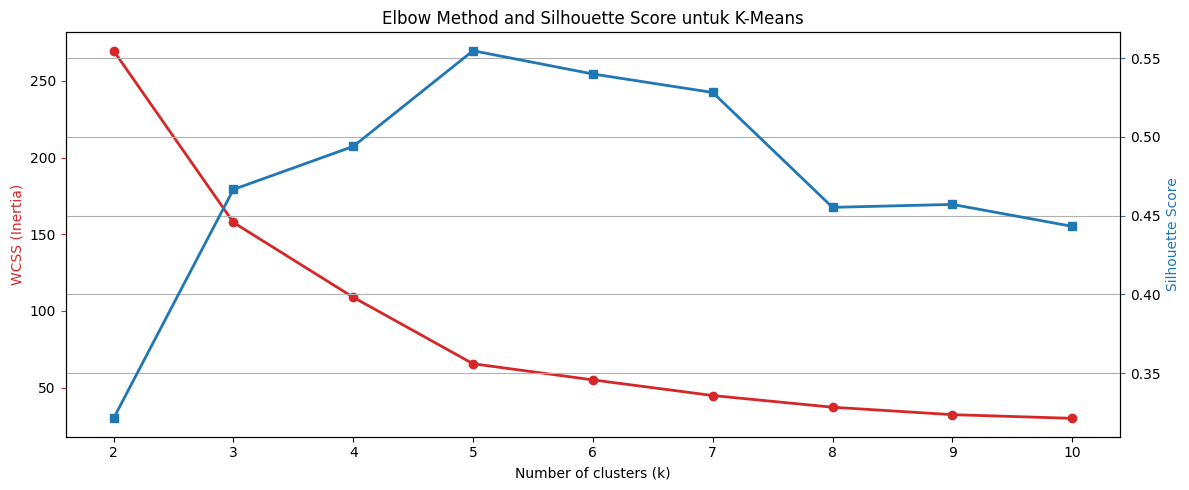

In [16]:
wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_kmeans_scaled)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_kmeans_scaled, kmeans.labels_))

# Plotting Elbow & Silhouette
fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:red'
ax1.set_xlabel('Number of clusters (k)')
ax1.set_ylabel('WCSS (Inertia)', color=color)
ax1.plot(k_range, wcss, marker='o', color=color, linewidth=2)
ax1.tick_params(axis='y', color=color)
ax1.set_title('Elbow Method and Silhouette Score untuk K-Means')

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(k_range, silhouette_scores, marker='s', color=color, linewidth=2)
ax2.tick_params(axis='y', color=color)

fig.tight_layout()
plt.grid(True)
plt.show()


Berdasarkan grafik di atas, grafik siku (Elbow) mulai melandai secara signifikan pada k = 5, dan nilai Silhouette Score mencapai nilai tertinggi yang sangat stabil pada k = 5. Oleh karena itu, kita memilih k = 5 sebagai jumlah klaster terbaik.


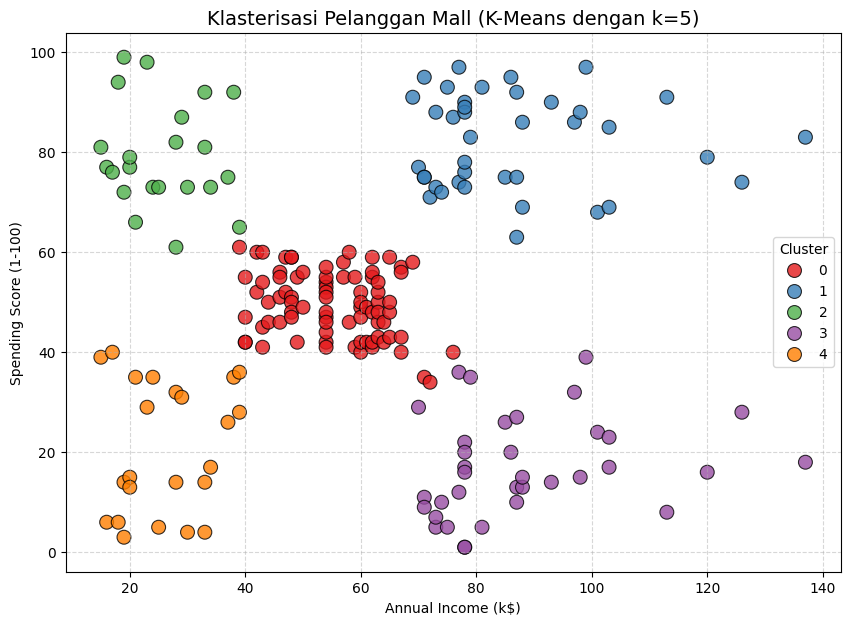

In [17]:
# Melatih model K-Means dengan k=5
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X_kmeans_scaled)

# Visualisasi Klaster
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_kmeans[:, 0], y=X_kmeans[:, 1],
    hue=y_kmeans, palette='Set1',
    s=100, edgecolor='black', alpha=0.8
)

plt.title('Klasterisasi Pelanggan Mall (K-Means dengan k=5)', fontsize=14)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


JAWABAN TUGAS 2 DBSCAN (make_moons)


In [24]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN
from sklearn import metrics

# 1. Membuat dataset make_moons (1000 sampel, noise=0.05)
X_moons, y_moons = make_moons(n_samples=1000, noise=0.05, random_state=42)

# 2. Normalisasi menggunakan StandardScaler
scaler_dbscan = StandardScaler()
X_moons_scaled = scaler_dbscan.fit_transform(X_moons)

DBSCAN dengan Parameter Default Awal: eps=0.2, min_samples=5

In [25]:
# Inisialisasi dan fitting DBSCAN
db = DBSCAN(eps=0.2, min_samples=5).fit(X_moons_scaled)
labels = db.labels_

# Mengidentifikasi Core Samples, Non-Core Samples, dan Noise
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print(f"Jumlah Klaster: {n_clusters_}")
print(f"Jumlah Noise: {n_noise_}")

Jumlah Klaster: 2
Jumlah Noise: 0


Evaluasi Metrik DBSCAN Awal


In [26]:
print("Evaluasi Metrik DBSCAN (eps=0.2, min_samples=5):")
print(f"Homogeneity: {metrics.homogeneity_score(y_moons, labels):.4f}")
print(f"Completeness: {metrics.completeness_score(y_moons, labels):.4f}")
print(f"V-measure: {metrics.v_measure_score(y_moons, labels):.4f}")
print(f"Adjusted Rand Index (ARI): {metrics.adjusted_rand_score(y_moons, labels):.4f}")
print(f"Adjusted Mutual Information (AMI): {metrics.adjusted_mutual_info_score(y_moons, labels):.4f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X_moons_scaled, labels):.4f}")

Evaluasi Metrik DBSCAN (eps=0.2, min_samples=5):
Homogeneity: 1.0000
Completeness: 1.0000
V-measure: 1.0000
Adjusted Rand Index (ARI): 1.0000
Adjusted Mutual Information (AMI): 1.0000
Silhouette Coefficient: 0.3912


Visualisasi Hasil DBSCAN
* Core Samples: Titik berukuran besar
* Non-Core Samples: Titik berukuran kecil
* Noise: Berwarna hitam (k)


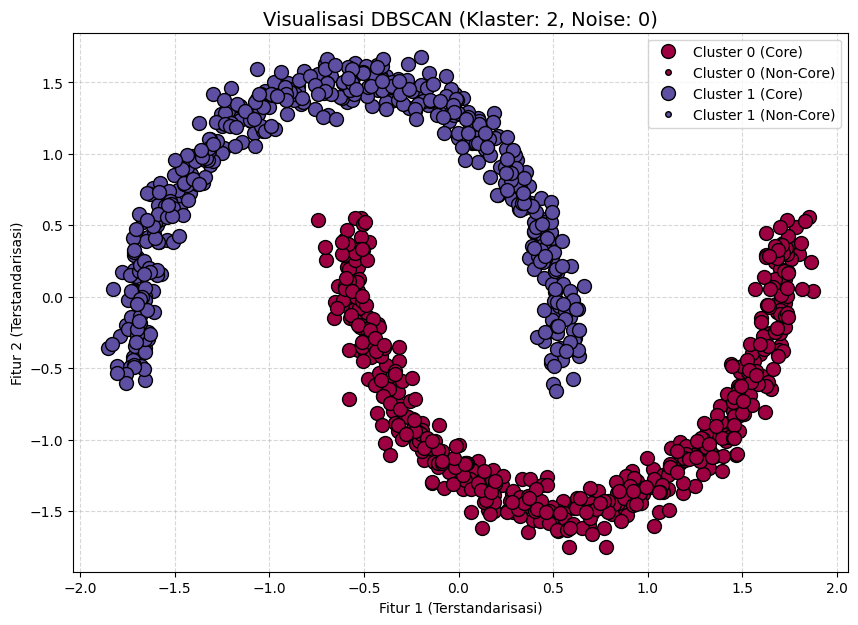

In [27]:
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

plt.figure(figsize=(10, 7))

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Warna hitam untuk noise
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    # Plot Core Samples (Titik Besar)
    xy_core = X_moons_scaled[class_member_mask & core_samples_mask]
    plt.plot(
        xy_core[:, 0], xy_core[:, 1], 'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k', markersize=10,
        label=f'Cluster {k} (Core)' if k != -1 else None
    )

    # Plot Non-Core Samples (Titik Kecil)
    xy_non_core = X_moons_scaled[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy_non_core[:, 0], xy_non_core[:, 1], 'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k', markersize=4,
        label=f'Cluster {k} (Non-Core)' if k != -1 else 'Noise' if k == -1 else None
    )

plt.title(f'Visualisasi DBSCAN (Klaster: {n_clusters_}, Noise: {n_noise_})', fontsize=14)
plt.xlabel('Fitur 1 (Terstandarisasi)')
plt.ylabel('Fitur 2 (Terstandarisasi)')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Eksperimen Parameter DBSCAN
Kita akan menguji kombinasi:
* eps = [0.05, 0.1, 0.3, 0.5]
* min_samples = [3, 10, 20]

Lalu, mencatat hasil perubahan klaster, noise, dan metrik evaluasi ke dalam sebuah DataFrame.


In [28]:
eps_values = [0.05, 0.1, 0.3, 0.5]
min_samples_values = [3, 10, 20]
results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        db_exp = DBSCAN(eps=eps, min_samples=min_samples).fit(X_moons_scaled)
        labels_exp = db_exp.labels_

        # Hitung klaster dan noise
        n_clusters_exp = len(set(labels_exp)) - (1 if -1 in labels_exp else 0)
        n_noise_exp = list(labels_exp).count(-1)

        # Hitung metrik evaluasi jika terdapat minimal 2 klaster (dan tidak semuanya dianggap noise)
        if n_clusters_exp > 0 and len(set(labels_exp)) > 1:
            homo = metrics.homogeneity_score(y_moons, labels_exp)
            comp = metrics.completeness_score(y_moons, labels_exp)
            v_meas = metrics.v_measure_score(y_moons, labels_exp)
            ari = metrics.adjusted_rand_score(y_moons, labels_exp)
            ami = metrics.adjusted_mutual_info_score(y_moons, labels_exp)
            sil = metrics.silhouette_score(X_moons_scaled, labels_exp)
        else:
            homo, comp, v_meas, ari, ami, sil = [np.nan] * 6

        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Clusters': n_clusters_exp,
            'Noise': n_noise_exp,
            'Homogeneity': homo,
            'Completeness': comp,
            'V-measure': v_meas,
            'ARI': ari,
            'AMI': ami,
            'Silhouette': sil
        })

df_results = pd.DataFrame(results)
display(df_results)

,eps,min_samples,Clusters,Noise,Homogeneity,Completeness,V-measure,ARI,AMI,Silhouette
0,0.05,3,69,186,0.815554,0.152548,0.257021,0.030044,0.243805,0.112929
1,0.05,10,3,970,0.030669,0.126764,0.049389,0.002283,0.045864,-0.294190
2,0.05,20,0,1000,NaN,NaN,NaN,NaN,NaN,NaN
3,0.10,3,2,14,0.986207,0.902896,0.942714,0.972179,0.942634,0.251690
4,0.10,10,7,57,0.943317,0.409546,0.571132,0.523399,0.569801,0.162306
5,0.10,20,6,850,0.153928,0.155466,0.154693,0.016754,0.150916,-0.360195
6,0.30,3,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160
7,0.30,10,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160
8,0.30,20,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160
9,0.50,3,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160
